In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Magnitude-based router results

## Predictor performance

In [41]:
all_results = pd.read_csv('results/prediction_results.csv', index_col=0)

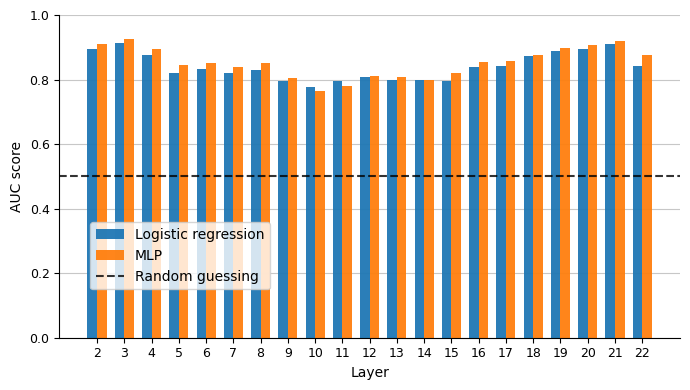

In [66]:
layers = list(all_results.index)
x = np.arange(len(layers))  # positions for the bars
width = 0.35  # width of the bars

plt.figure(figsize=(7, 4))

# Bar plots for logistic regression and MLP
bar1 = plt.bar(x - width/2, all_results['AUC'], width, alpha=0.95)
bar2 = plt.bar(x + width/2, all_results['AUC_mlp'], width, alpha=0.95)
# Horizontal line for random guessing
line = plt.axhline(0.5, linestyle='--', color='black', alpha=0.8)

plt.legend([bar1, bar2, line],
           ['Logistic regression', 'MLP', 'Random guessing'],
           loc=(0.05, 0.15))

# plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('AUC score')
plt.ylim(0, 1)
plt.xticks(x, layers, fontsize=9)
plt.yticks([i/10 for i in range(0, 11, 2)], fontsize=9)
# plt.legend(loc=(0.05, 0.15))
plt.grid(axis='y', linestyle='-', alpha=0.7)

ax = plt.gca()
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

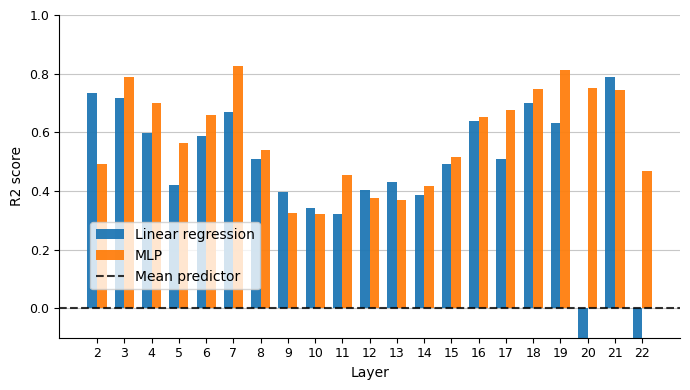

In [70]:
layers = list(all_results.index)
x = np.arange(len(layers))  # positions for the bars
width = 0.35  # width of the bars

plt.figure(figsize=(7, 4))

# Bar plots for logistic regression and MLP
bar1 = plt.bar(x - width/2, all_results['R2'], width, alpha=0.95)
bar2 = plt.bar(x + width/2, all_results['R2_mlp'], width, alpha=0.95)
# Horizontal line for random guessing
line = plt.axhline(0, linestyle='--', color='black', alpha=0.8)

plt.legend([bar1, bar2, line],
           ['Linear regression', 'MLP', 'Mean predictor'],
           loc=(0.05, 0.15))

# plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('R2 score')
plt.ylim(-0.1, 1)
plt.xticks(x, layers, fontsize=9)
plt.yticks([i/10 for i in range(0, 11, 2)], fontsize=9)
# plt.legend(loc=(0.05, 0.15))
plt.grid(axis='y', linestyle='-', alpha=0.7)

ax = plt.gca()
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

In [71]:
all_results

,lr,R2,AUC,lr_mlp,R2_mlp,AUC_mlp
2,0.0001/100,0.732842,0.893460,0.001/10,0.490985,0.911036
3,0.001/100,0.715495,0.913248,0.0001/10,0.788626,0.925901
4,0.001/100,0.598657,0.874551,0.0001/10,0.700460,0.893220
5,0.001/100,0.420369,0.821593,0.0001/10,0.562346,0.844120
6,0.001/100,0.586555,0.832349,0.001/10,0.657848,0.852590
7,0.0001/10,0.670469,0.819494,0.001/10,0.826647,0.839540
8,0.001/100,0.509489,0.828829,0.0001/10,0.540035,0.851315
9,0.001/10,0.398353,0.797029,0.0001/10,0.326592,0.806142
10,0.001/10,0.342711,0.778206,0.0001/10,0.322642,0.765952
11,0.001/10,0.320365,0.796386,0.0001/100,0.455345,0.780209


## Router performance

In [4]:
block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24
wrell2 = pd.read_csv('results/results_w_rel_L2.csv', index_col=0)
wrell2['del_ratio'] = wrell2.index / 24

small_changes = pd.read_csv('results/results_threshold_rel_except.csv', index_col=0, header=[0, 1])
small_changes = small_changes.loc[:, [('perplexity', 'L1'), ('ratio_del', 'L1')]]

results = {}
results['r'] = pd.read_csv('results/results_router.csv', index_col=0)
results['topk'] = pd.read_csv('results/results_router_topk.csv', index_col=[0, 1])
results['thr'] = pd.read_csv('results/results_router_thr.csv', index_col=0)
results['singleskip'] = pd.read_csv('results/results_singleskip_router.csv', index_col=0)
results['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk.csv', index_col=[0, 1])
results['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router.csv', index_col=0)

results_v2 = {}
results_v2['r'] = pd.read_csv('results/results_router_v2.csv', index_col=0)
results_v2['thr'] = pd.read_csv('results/results_router_thr_v2.csv', index_col=0)
results_v2['singleskip'] = pd.read_csv('results/results_singleskip_router_v2.csv', index_col=0)
results_v2['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v2.csv', index_col=[0, 1])
results_v2['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router_v2.csv', index_col=0)

results_v3 = {}
results_v3['singleskip'] = pd.read_csv('results/results_singleskip_router_v3ss.csv', index_col=0)
results_v3['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v3ss.csv', index_col=[0, 1])

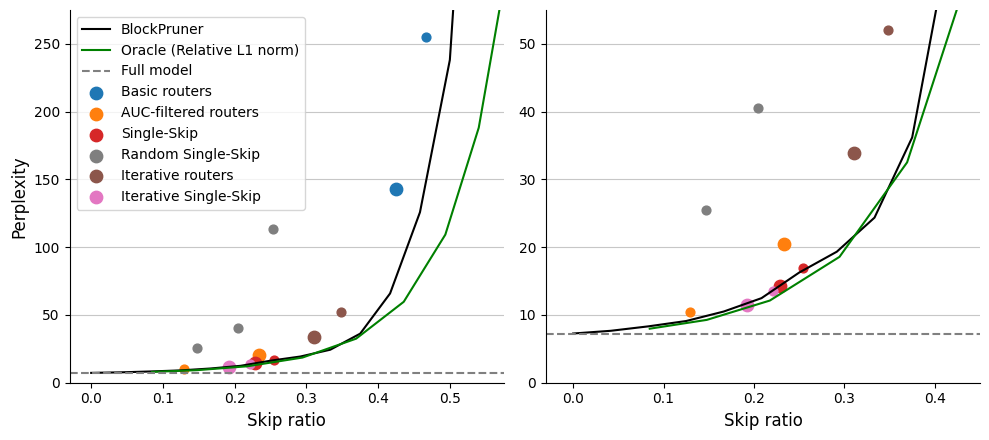

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=False)

# ---------- LEFT SUBPLOT ----------
ax = axes[0]

ax.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], 
        c='black', label='BlockPruner')
ax.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], 
        c='g', label='Oracle (Relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], 
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], 
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], 
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], 
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], 
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], 
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], 
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], 
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], 
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], 
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], 
           s=80, c='tab:pink', label='Iterative Single-Skip')

ax.set_xlim((-0.03, 0.575))
ax.set_ylim((0, 275))
ax.set_xlabel('Skip ratio', fontsize=12)
ax.set_ylabel('Perplexity', fontsize=12)

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.legend()

# ---------- RIGHT SUBPLOT ----------
ax = axes[1]

ax.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], 
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], 
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'],
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'],
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'],
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'],
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'],
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'],
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'],
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:pink', label='Iterative Single-Skip')

ax.set_xlim((-0.03, 0.45))
ax.set_ylim((0, 55))
ax.set_xlabel('Skip ratio', fontsize=12)
# ax.set_ylabel('Perplexity')

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()

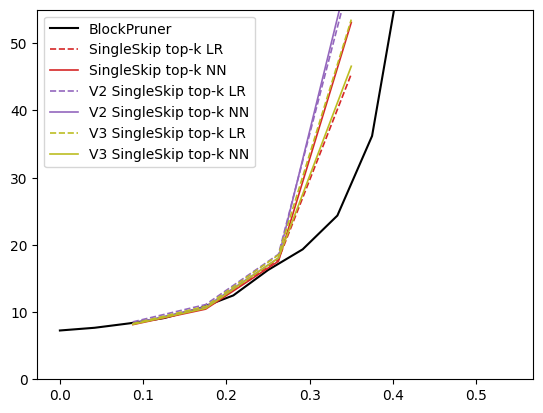

In [8]:
###
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')

ss_topk_lr = results['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:red', ls='--', lw=1.2, label='SingleSkip top-k LR')
ss_topk_nn = results['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:red', lw=1.2, label='SingleSkip top-k NN')

ss_topk_lr = results_v2['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:purple', ls='--', lw=1.2, label='V2 SingleSkip top-k LR')
ss_topk_nn = results_v2['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:purple', lw=1.2, label='V2 SingleSkip top-k NN')

ss_topk_lr = results_v3['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:olive', ls='--', lw=1.2, label='V3 SingleSkip top-k LR')
ss_topk_nn = results_v3['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:olive', lw=1.2, label='V3 SingleSkip top-k NN')

plt.ylim((0, 55))
plt.legend();

# Gate Results (trained using cross-entropy loss)

In [3]:
gate_results = pd.read_csv('results/gate_training.csv', index_col=0)

In [6]:
gated_model_results = pd.concat([
    gate_results.loc[
        (gate_results.n_samples == nsamp) &
        (gate_results.skip_ratio > (skip / 100)) &
        (gate_results.skip_ratio < ((skip + 3.5) / 100))
    ]
    .sort_values("val_ppl")
    .head(1)
    .assign(skip=skip)   # store row label
    for skip in range(20, 31, 5)
    for nsamp in (128, 256, 512)
], ignore_index=True).drop_duplicates()

gated_model_results = gated_model_results.set_index("skip")

In [7]:
dfs = []

for n in [128, 256, 512]:
    df = (
        gated_model_results
        .query("n_samples == @n")[['val_ppl', 'skip_ratio']]
    )
    # add top-level header
    df.columns = pd.MultiIndex.from_product([[n], df.columns])
    dfs.append(df)

pd.concat(dfs, axis=1).round(2)

128                256                512           
     val_ppl skip_ratio val_ppl skip_ratio val_ppl skip_ratio
skip                                                         
20     21.95       0.20   17.96       0.20   32.75       0.23
25     21.53       0.25   33.51       0.27   25.51       0.26
30    760.74       0.31   25.23       0.30   32.60       0.31

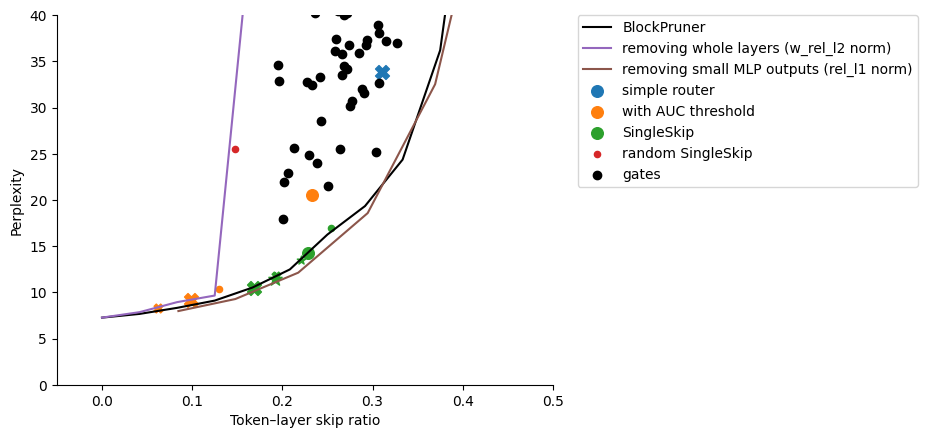

In [67]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results.skip_ratio, gate_results.val_ppl, c='black', label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 40))

plt.xlabel('Token–layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

In [70]:
gate_results.sort_values(by="val_ppl").head(10)

,target_skip,grad_accum_steps,run_i,val_ppl,skip_ratio,n_samples
lr,,,,,,
0.005,0.30,4.0,0.0,17.959000,0.200867,256.0
0.007,0.30,1.0,1.0,21.534990,0.250982,128.0
0.007,0.30,4.0,2.0,21.948141,0.201940,128.0
0.005,0.30,4.0,2.0,22.943251,0.206680,256.0
0.010,0.30,1.0,2.0,23.993603,0.238632,128.0
0.010,0.35,4.0,2.0,24.839018,0.229101,128.0
0.005,0.35,4.0,0.0,25.230175,0.303828,256.0
0.007,0.30,4.0,0.0,25.508720,0.263870,512.0
0.007,0.30,4.0,1.0,25.573433,0.213099,256.0


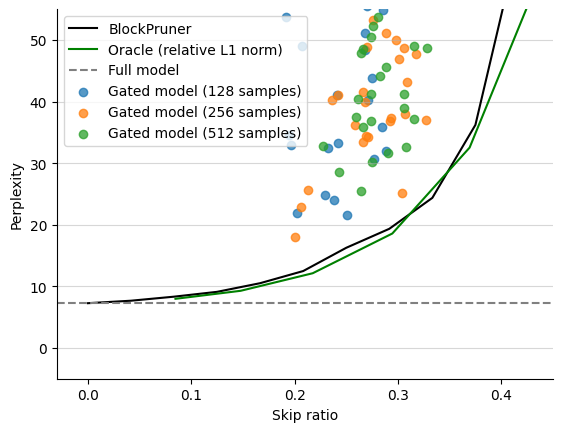

In [17]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        c='g', label='Oracle (relative L1 norm)')

plt.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"Gated model ({int(x)} samples)", alpha=0.75)
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Perplexity")
plt.legend(title=param)
# plt.legend(loc="lower right")
plt.legend(loc="upper left")
sns.despine()
plt.show()

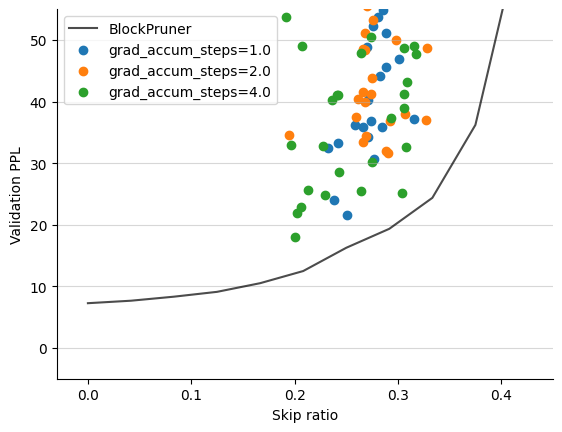

In [72]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

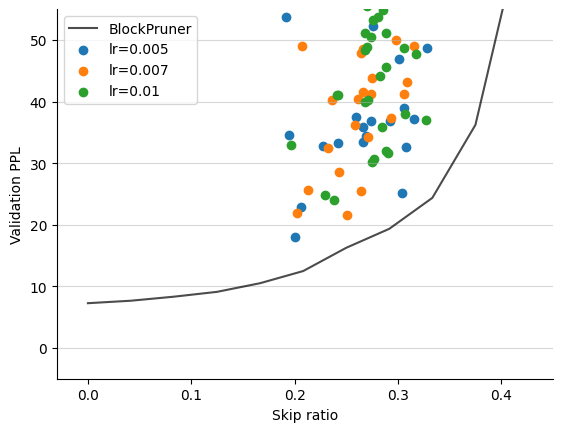

In [73]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
param = "lr" # 0.005
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

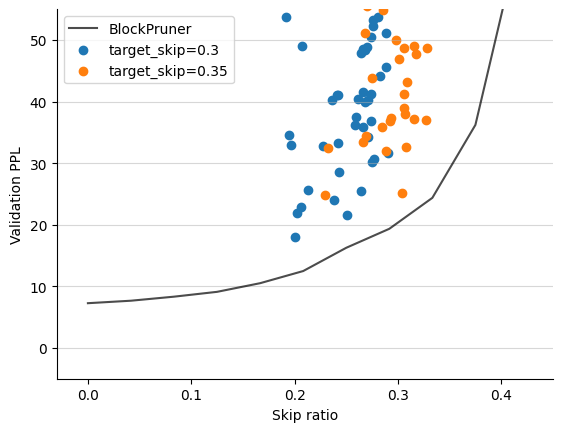

In [74]:
# results_df = gate_results.query('n_samples==256')
results_df = gate_results
# param = "n_samples"  # 4
# param = "grad_accum_steps"  # 4
# param = "lr" # 0.005
param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

# New gate results (trained using KL divergence, separate param groups)

In [75]:
gate_results = pd.concat([
    pd.read_csv('results/kl_gate_training_128.csv'), 
    pd.read_csv('results/kl_gate_training_256.csv'), 
    pd.read_csv('results/kl_gate_training_512.csv')
])
gate_results.to_csv('results/kl_gate_training.csv', index=False)

In [76]:
gate_results.loc[(gate_results['skip_ratio'] > 0.25) & (gate_results['val_ppl'] < 60)].sort_values(by='val_ppl')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
24,512.0,1.0,1.000000e-02,0.0,10.662846,0.252162,0.3,0.3
78,512.0,1.0,1.000000e-02,1.0,10.899587,0.256897,0.5,0.3
26,512.0,1.0,1.000000e-02,2.0,10.913402,0.251714,0.3,0.3
25,512.0,1.0,1.000000e-02,1.0,11.036218,0.256231,0.3,0.3
85,512.0,0.1,1.000000e-02,0.0,11.085263,0.255686,0.5,0.3
...,...,...,...,...,...,...,...,...
123,512.0,0.1,1.000000e-03,0.0,55.200920,0.437129,0.5,0.5
18,128.0,10.0,1.000000e-08,0.0,55.575165,0.291743,0.3,0.3
30,256.0,10.0,1.000000e-04,0.0,55.692631,0.345398,0.3,0.4
140,128.0,1.0,1.000000e-02,1.0,57.752445,0.447881,0.3,0.5


In [77]:
# results_df = gate_results.loc[(gate_results['skip_ratio'] > 0.25) & (gate_results['val_ppl'] < 60) & (gate_results['n_samples'] == 128)].sort_values(by='val_ppl')
results_df = gate_results

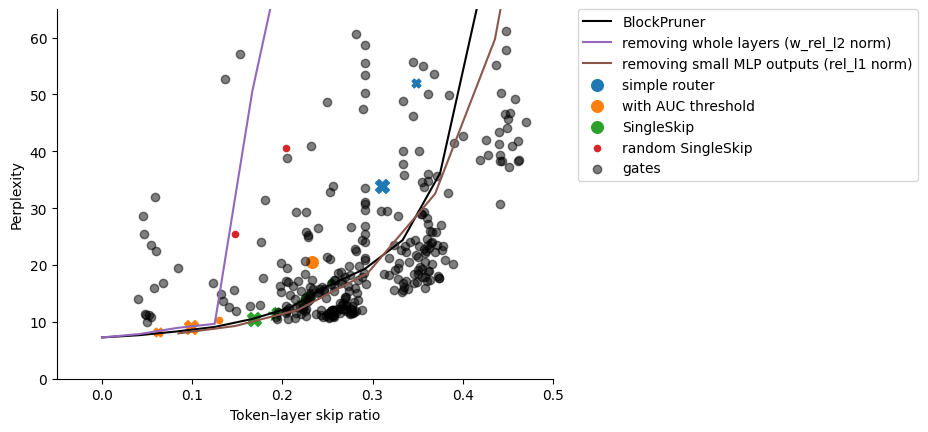

In [78]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results.skip_ratio, gate_results.val_ppl, c='black', alpha=0.5, label='gates')

# plt.scatter(gate_results_best.skip_ratio, gate_results_best.val_ppl, c='black', alpha=0.5, label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 65))

plt.xlabel('Token–layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

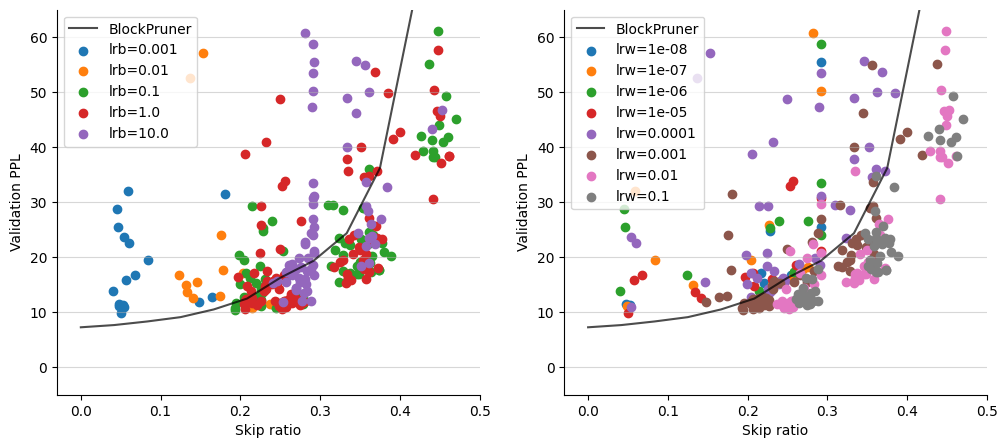

In [79]:
# results_df = gate_results
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for i, param in enumerate(("lrb", "lrw")):
    ax[i].plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
    for x, group in results_df.groupby(param):
        ax[i].scatter(group["skip_ratio"], group["val_ppl"],
                    label=f"{param}={x}")
    ax[i].set_xlim((-0.03, 0.5))
    ax[i].set_ylim((-5, 65))
    ax[i].grid(axis='y', alpha=0.5)
    ax[i].set_xlabel("Skip ratio")
    ax[i].set_ylabel("Validation PPL")
    ax[i].legend(title=param)
    ax[i].legend(loc="upper left")
    sns.despine()


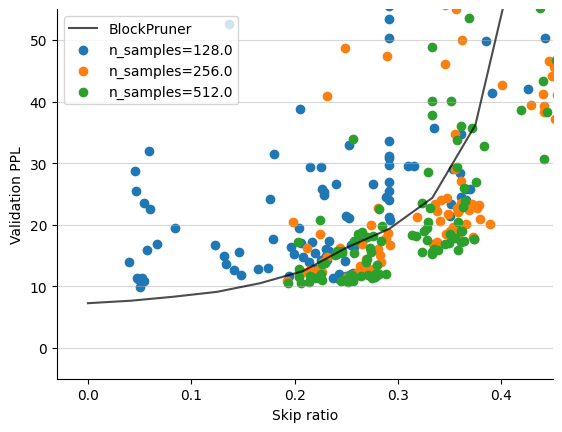

In [80]:
results_df = gate_results
param = "n_samples"
# param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
plt.xlim((-0.03, 0.45))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

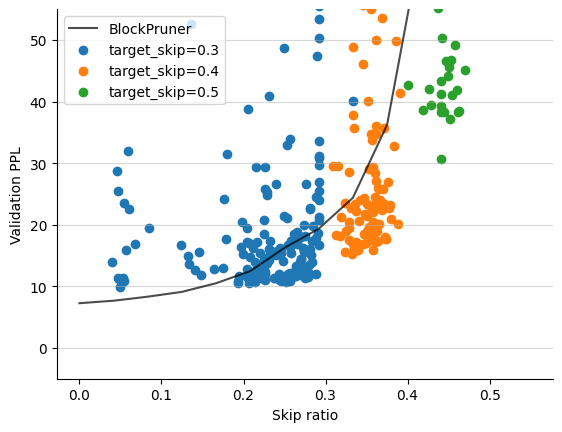

In [81]:
# results_df = gate_results
# param = "n_samples"
param = "target_skip"
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', alpha=0.7, label='BlockPruner')
for x, group in results_df.groupby(param):
    plt.scatter(group["skip_ratio"], group["val_ppl"],
                label=f"{param}={x}")
# plt.xlim((-0.03, 0.65))
plt.ylim((-5, 55))
plt.grid(axis='y', alpha=0.5)
plt.xlabel("Skip ratio")
plt.ylabel("Validation PPL")
plt.legend(title=param)
plt.legend(loc="upper left")
sns.despine()
plt.show()

## Router Comparison - Selected gates

In [82]:
gate_results_best = gate_results.loc[
    gate_results['lrb'].isin([10, 1, 0.1])
    & gate_results['lrw'].isin([1e-1, 1e-2, 1e-3])
    & (gate_results['val_ppl'] < 60) 
]

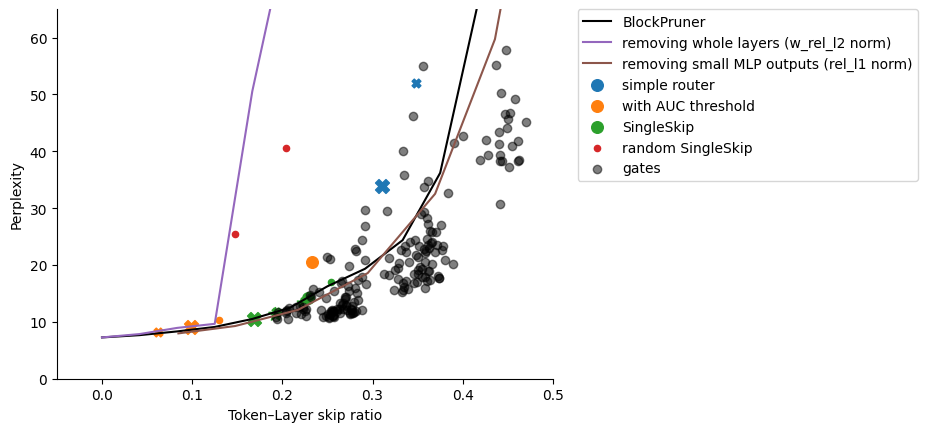

In [83]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

###

plt.scatter(gate_results_best.skip_ratio, gate_results_best.val_ppl, c='black', alpha=0.5, label='gates')

###

plt.xlim((-0.05, 0.5))
plt.ylim((0, 65))

plt.xlabel('Token–Layer skip ratio')
plt.ylabel('Perplexity')

# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
sns.despine();

In [84]:
gate_results_best.loc[
    (gate_results_best['skip_ratio'] > 0.3) 
    & (gate_results_best['val_ppl'] < 60)
].sort_values(by='val_ppl')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip
54,512.0,1.0,0.010,1.0,15.315804,0.332835,0.3,0.4
61,512.0,0.1,0.010,0.0,15.537294,0.323583,0.3,0.4
62,512.0,0.1,0.010,1.0,15.649241,0.333262,0.3,0.4
102,512.0,1.0,0.010,1.0,15.842070,0.339157,0.5,0.4
101,512.0,1.0,0.010,0.0,15.962949,0.358022,0.5,0.4
...,...,...,...,...,...,...,...,...
64,256.0,0.1,0.100,0.0,49.231682,0.458099,0.3,0.5
139,128.0,1.0,0.010,0.0,50.324730,0.442413,0.3,0.5
29,256.0,10.0,0.001,1.0,54.991535,0.356018,0.3,0.4
123,512.0,0.1,0.001,0.0,55.200920,0.437129,0.5,0.5


## Final

In [2]:
gate_results = pd.concat([
    pd.read_csv('results/kl_gate_training.csv'),
    pd.read_csv('results/model_stats_results.csv')
])

### Top model selection

In [3]:
gated_model_results = pd.concat([
    gate_results.loc[(gate_results.n_samples==nsamp) & (gate_results.skip_ratio>(skip/100))
        & (gate_results.skip_ratio<((skip+5)/100))
    ].sort_values(by='val_ppl').head(2) 
    for skip in range(15, 47) for nsamp in (128, 256, 512)
], ignore_index=True).drop_duplicates()

In [4]:
gated_model_results.sort_values(by='skip_ratio')

,n_samples,lrb,lrw,run_i,val_ppl,skip_ratio,init_skip,target_skip,run_id
1,128.0,0.001,0.0010,0.0,12.837427,0.164434,0.3,0.3,NaN
2,256.0,0.100,0.0010,0.0,10.787396,0.192891,0.3,0.3,NaN
4,512.0,0.100,0.0010,0.0,10.493101,0.193731,0.5,0.3,NaN
0,128.0,0.100,0.0010,2.0,11.659032,0.195023,0.3,0.3,NaN
3,256.0,0.100,0.0001,0.0,20.393225,0.198532,0.3,0.3,NaN
...,...,...,...,...,...,...,...,...,...
182,256.0,1.000,0.0100,0.0,38.374062,0.461812,0.5,0.5,NaN
183,512.0,1.000,0.1000,0.0,38.455173,0.462199,0.5,0.5,NaN
188,256.0,0.100,0.1000,1.0,45.148918,0.470240,0.5,0.5,NaN
186,128.0,1.000,0.1000,1.0,6672.455566,0.472397,0.3,0.5,NaN


### Visualization

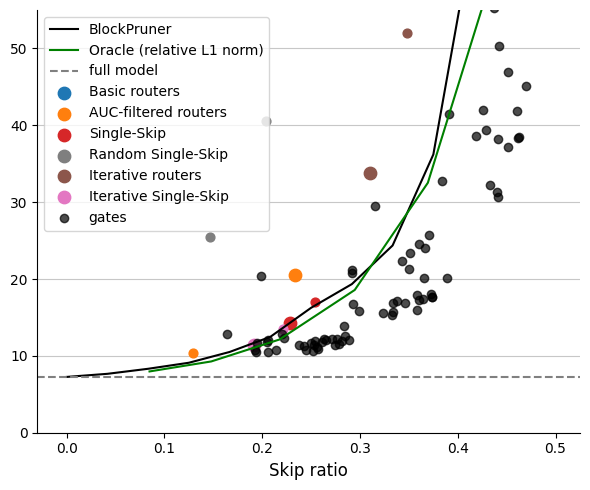

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=False)

ax.plot(block_pruner.loc[:13, 'del_ratio'],
        block_pruner.loc[:13, 'perplexity'],
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='full model')

ax.scatter(results['r'].loc['lr', 'del_ratio'],
           results['r'].loc['lr', 'perplexity'],
           s=40, c='tab:blue')
ax.scatter(results['r'].loc['nn', 'del_ratio'],
           results['r'].loc['nn', 'perplexity'],
           s=80, c='tab:blue', label='Basic routers')

ax.scatter(results['thr'].loc['lr', 'del_ratio'],
           results['thr'].loc['lr', 'perplexity'],
           s=40, c='tab:orange')
ax.scatter(results['thr'].loc['nn', 'del_ratio'],
           results['thr'].loc['nn', 'perplexity'],
           s=80, c='tab:orange', label='AUC-filtered routers')

ax.scatter(results['singleskip'].loc['lr', 'del_ratio'],
           results['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:red')
ax.scatter(results['singleskip'].loc['nn', 'del_ratio'],
           results['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:red', label='Single-Skip')

ax.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'],
           results['singleskip_rnd'].loc[:, 'perplexity'],
           s=40, c='tab:gray')
ax.scatter([], [], s=80, c='tab:gray', label='Random Single-Skip')

ax.scatter(results_v2['r'].loc['lr', 'del_ratio'],
           results_v2['r'].loc['lr', 'perplexity'],
           s=40, c='tab:brown')
ax.scatter(results_v2['r'].loc['nn', 'del_ratio'],
           results_v2['r'].loc['nn', 'perplexity'],
           s=80, c='tab:brown', label='Iterative routers')

ax.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'],
           results_v3['singleskip'].loc['lr', 'perplexity'],
           s=40, c='tab:pink')
ax.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'],
           results_v3['singleskip'].loc['nn', 'perplexity'],
           s=80, c='tab:pink', label='Iterative Single-Skip')

### gates
plt.scatter(gated_model_results.skip_ratio, gated_model_results.val_ppl, c='black', alpha=0.7, label='gates')

######

ax.set_xlim((-0.03, 0.525))
ax.set_ylim((0, 55))
ax.set_xlabel('Skip ratio', fontsize=12)
# ax.set_ylabel('Perplexity')

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax.legend()

plt.tight_layout()

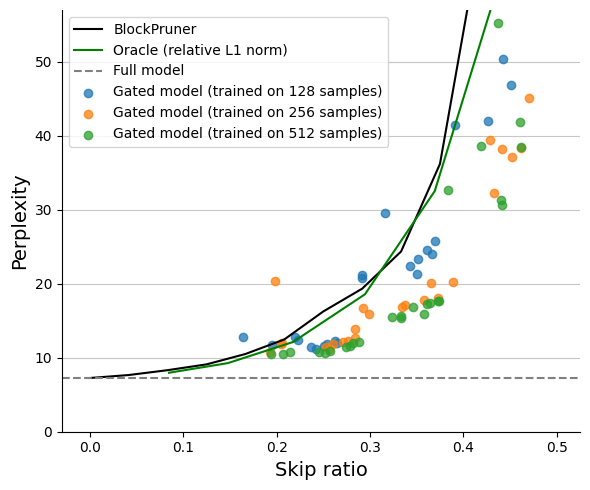

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=False)

ax.plot(block_pruner.loc[:13, 'del_ratio'],
        block_pruner.loc[:13, 'perplexity'],
        c='black', label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        c='g', label='Oracle (relative L1 norm)')

ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')


### gates
param = "n_samples"
for x, group in gated_model_results.groupby(param):
    ax.scatter(group["skip_ratio"], group["val_ppl"],
               # label=f"{param}={x}", alpha=0.75)
               label=f"Gated model (trained on {int(x)} samples)", alpha=0.75)
######

ax.set_xlim((-0.03, 0.525))
ax.set_ylim((0, 57))
ax.set_xlabel('Skip ratio', fontsize=12)
ax.set_ylabel('Perplexity', fontsize=12)

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax.legend()

plt.tight_layout()

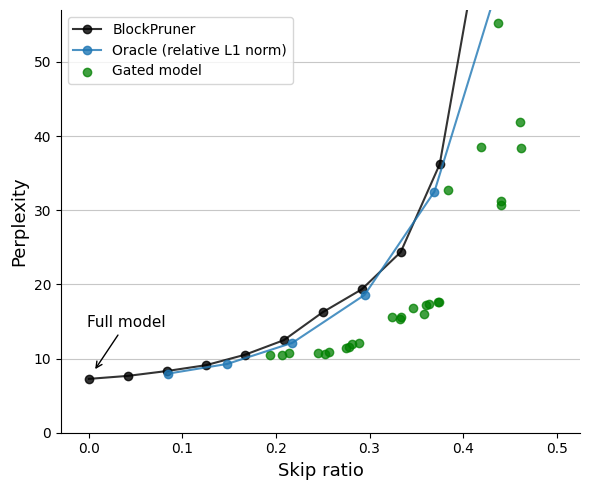

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(6, 5), sharey=False)

ax.plot(block_pruner.loc[:13, 'del_ratio'],
        block_pruner.loc[:13, 'perplexity'],
        c='black', marker='o', alpha=0.8, label='BlockPruner')

ax.plot(small_changes.loc[:, 'ratio_del'],
        small_changes.loc[:, 'perplexity'],
        marker='o', alpha=0.8, label='Oracle (relative L1 norm)')

# ax.axhline(block_pruner.loc[0, 'perplexity'], c='gray', linestyle='--', label='Full model')


### gates
group = gated_model_results.loc[gated_model_results['n_samples'] == 512]
ax.scatter(group["skip_ratio"], group["val_ppl"], c='g', label="Gated model", alpha=0.75)
######

ax.set_xlim((-0.03, 0.525))
ax.set_ylim((0, 57))

full_ppl = block_pruner.loc[0, 'perplexity']

ax.annotate(
    'Full model',
    xy=(0.005, full_ppl+1),
    xytext=(0.04, full_ppl + 7),
    arrowprops=dict(arrowstyle='->', color='black'),
    fontsize=11,
    ha='center'
)

ax.set_xlabel('Skip ratio', fontsize=13)
ax.set_ylabel('Perplexity', fontsize=13)

ax.grid(axis='y', linestyle='-', alpha=0.7)
ax.set_axisbelow(True)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


ax.legend()

plt.tight_layout()
plt.savefig('gates.png')

### Top Model Table

In [22]:
gated_model_results = pd.concat([
    gate_results.loc[
        (gate_results.n_samples == nsamp) &
        (gate_results.skip_ratio > (skip / 100)) &
        (gate_results.skip_ratio < ((skip + 3.5) / 100))
    ]
    .sort_values("val_ppl")
    .head(1)
    .assign(skip=skip)   # store row label
    for skip in range(20, 46, 5)
    for nsamp in (128, 256, 512)
], ignore_index=True).drop_duplicates()

gated_model_results = gated_model_results.set_index("skip")

In [23]:
dfs = []

for n in [128, 256, 512]:
    df = (
        gated_model_results
        .query("n_samples == @n")[['val_ppl', 'skip_ratio']]
    )
    # add top-level header
    df.columns = pd.MultiIndex.from_product([[n], df.columns])
    dfs.append(df)

pd.concat(dfs, axis=1).round(2)

128                256                512           
     val_ppl skip_ratio val_ppl skip_ratio val_ppl skip_ratio
skip                                                         
20     12.35       0.22   11.84       0.20   10.52       0.21
25     11.61       0.25   11.14       0.26   10.66       0.25
30     29.50       0.32   16.91       0.33   15.32       0.33
35     21.34       0.35   17.86       0.36   15.96       0.36
40     41.99       0.43   32.23       0.43   38.55       0.42
45     46.90       0.45   37.16       0.45   38.46       0.46